In [20]:
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

In [12]:
DATA_PATH = Path('./data')
DATA_FILE = DATA_PATH / 'spike_data.npz'

In [ ]:
t = []
spikes = []
with np.load(DATA_FILE) as data:
    t = data["t"]
    spikes = data["raw_data"]

print(t)
print(spikes)

[0.000e+00 1.000e-03 2.000e-03 ... 9.997e+00 9.998e+00 9.999e+00]
[ 0.20712082 -0.08050916 -0.22675921 ... -0.46945475  0.21566286
 -0.23607432]


In [44]:
print(f"T:\n Period Of Observation: {np.max(t)}, \n Frequency: {np.mean(np.diff(t))}")
print(f"Spikes:\n Min: {np.min(spikes)},\n Max: {np.max(spikes)},\n Mean: {np.mean(spikes)},\n Std: {np.std(spikes)},\n Points: {len(spikes)}")

T:
 Period Of Observation: 9.999, 
 Frequency: 0.001
Spikes:
 Min: -1.69098912315189,
 Max: 6.201962575902169,
 Mean: 0.07688186859453115,
 Std: 0.734406036172483,
 Points: 10000


In [ ]:
spikes_series = pd.Series(spikes, index = t)

In [54]:
spikes_series

0.000    0.207121
0.001   -0.080509
0.002   -0.226759
0.003    0.093325
0.004    0.445211
           ...   
9.995   -0.256272
9.996   -0.501563
9.997   -0.469455
9.998    0.215663
9.999   -0.236074
Length: 10000, dtype: float64

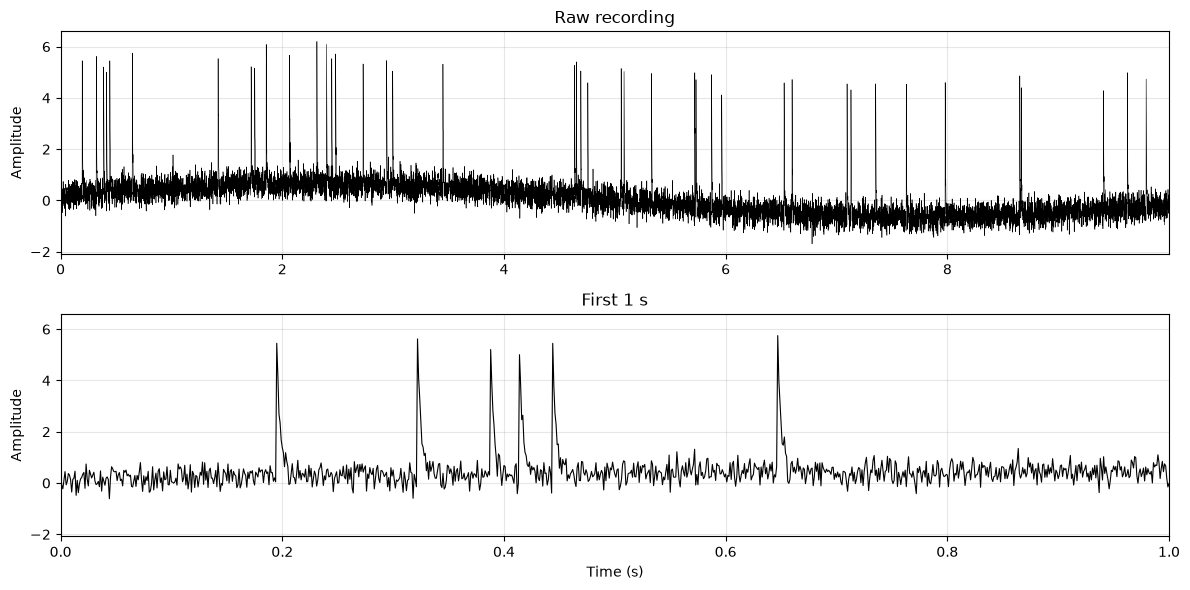

In [48]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharey=True)

axes[0].plot(t, spikes, color="black", linewidth=0.4)
axes[0].set_title("Raw recording")
axes[0].set_ylabel("Amplitude")
axes[0].set_xlim(t[0], t[-1])

zoom_end = 1
zoom = t <= zoom_end
axes[1].plot(t[zoom], spikes[zoom], color="black", linewidth=0.8)
axes[1].set_title(f"First {zoom_end} s")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Amplitude")
axes[1].set_xlim(t[0], zoom_end)

for ax in axes:
    ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

In [ ]:
window = 1000
z = (spikes_series - spikes_series.mean()) / spikes_series.std(ddof=0)
z.rolling(window=window, min_periods=1)
[spikes_series > z.mean()]

0.000     True
0.001    False
0.002    False
0.003     True
0.004     True
         ...  
9.995    False
9.996    False
9.997    False
9.998     True
9.999    False
Length: 10000, dtype: bool